# Modelo de nota do modo híbrido

No modo híbrido do bot, **a nota de cada competência do ENEM vem deste modelo**, e o LLM só escreve o comentário.
Este notebook refaz o modelo do zero: dos dados até a avaliação no teste e a checagem de que o resultado é o mesmo
modelo que roda no bot.

**A ideia em uma linha.** Um LLM pequeno e barato (o Jev) não dá a nota: ele responde 71 perguntas objetivas sobre a
redação ("a proposta tem um agente?", "o repertório é legitimado?"). As respostas viram colunas de uma tabela, junto
com medidas tiradas do próprio texto, e um modelo de árvores aprende a nota a partir delas.

**Roteiro**

1. Dados: como foram obtidos e o que tem no CSV
2. Divisão em treino, validação e teste
3. Features
4. Métricas
5. Escolha do modelo (treino → validação)
6. Calibração e soma exata
7. Avaliação final no teste
8. Temas que o modelo nunca viu
9. O que o modelo aprendeu
10. Modelo final e paridade com o bot
11. Limitações

**Para rodar:** `pip install -r notebooks/requirements.txt` e execute de dentro da pasta `notebooks/`. As versões de
`numpy` e `scikit-learn` são as mesmas do bot, para o resultado sair idêntico. Leva cerca de 45 minutos num computador
de 12 núcleos; só a seção 8 leva uns 18, e dá para desligá-la em `RODAR_TEMAS_INEDITOS`.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import RidgeCV
from sklearn.metrics import cohen_kappa_score
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Raiz do repositório: as features vêm do MESMO código que o bot usa em produção (src/correction/hybrid/).
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "correction" / "hybrid").is_dir())
sys.path.insert(0, str(RAIZ))
from src.correction.hybrid.deterministic import extrai
from src.correction.hybrid.features import engineered
from src.correction.hybrid.scoring import reconcile_qp

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 30, "display.width", 140, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

COMPS = ["c1", "c2", "c3", "c4", "c5"]
RODAR_TEMAS_INEDITOS = True

## 1. Dados

### Como os dados foram obtidos

1. **Redações e notas.** O corpus é o [Essay-BR](https://github.com/lplnufpi/essay-br) estendido (Marinho, Anchiêta
   & Moura, *JIDM* 2022; licença MIT, em `data/LICENSE-essay-br`): redações do site Brasil Escola, cada uma com a
   nota das 5 competências do ENEM (0 a 200, de 40 em 40). Ficam aqui as **6.475 com nota acima de zero**; as
   zeradas não entram no modelo, porque no bot a nota zero é decidida antes, por um portão de regras.
2. **Respostas do Jev.** Cada redação foi enviada, com o tema, ao Jev (`jev-1.14.0`, da TypeSafe AI) junto com 71
   perguntas objetivas. O texto de cada pergunta está em [`perguntas_jev.md`](perguntas_jev.md), ao lado do nome da
   coluna. O Jev responde cada pergunta de forma independente e devolve uma probabilidade (sim ou não), um nível
   contínuo (escalas de 0 a 5 ou de 0 a 2) ou uma probabilidade por opção. A coleta do corpus inteiro custou poucos
   dólares: só a entrada é cobrada.
3. **Tabela.** As respostas viraram 76 colunas `jev_*` e foram juntadas ao texto, ao tema, às notas e à divisão
   oficial do corpus. O resultado é o CSV abaixo, uma linha por redação, na ordem usada no treino.

In [2]:
df = pd.read_csv(RAIZ / "notebooks" / "data" / "essaybr_jev.csv.gz")
df["total"] = df[COMPS].sum(axis=1)
JEV_COLS = [c for c in df.columns if c.startswith("jev_")]

print(f"{len(df)} redações · {df.prompt_id.nunique()} temas · {len(JEV_COLS)} colunas do Jev")
df.assign(redacao=df.redacao.str.slice(0, 60) + "…", tema=df.tema.str.slice(0, 40))[
    ["id", "split", "tema", "redacao", *COMPS, "total", "jev_score_c1", "jev_c5_agente_especifico"]
].head(4)

6475 redações · 151 temas · 76 colunas do Jev


,id,split,tema,redacao,c1,c2,c3,c4,c5,total,jev_score_c1,jev_c5_agente_especifico
0,essaybr-86-4958,train,Impactos do uso das redes sociais na saú,É notório que as redes sociais estão cada vez ...,120,120,120,160,160,680,1.82,0.94
1,essaybr-86-4759,train,Impactos do uso das redes sociais na saú,Com o avanço das tecnologias ao redor do mundo...,200,160,160,200,160,880,3.64,0.98
2,essaybr-47-3949,train,Desafios na Educação a Distância no Bras,A declaração universal dos direitos humanos af...,160,160,160,160,160,800,3.41,0.97
3,essaybr-89-5015,train,Conscientização da população para o isol,"Barão de Itararé, um dos criadores do jornalis...",160,160,160,200,200,880,2.49,0.96


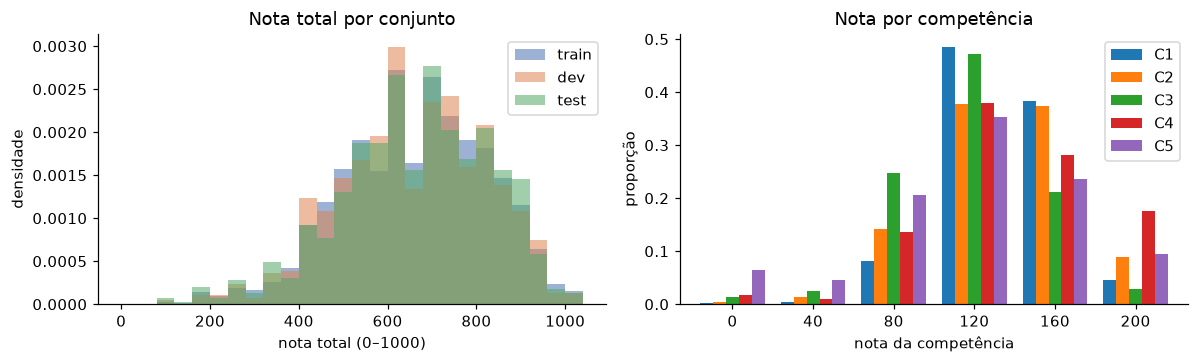

,c1,c2,c3,c4,c5,total
mean,135.141,134.629,117.208,136.951,117.418,641.347
std,29.315,36.572,35.857,42.699,50.225,164.387
min,0.000,0.000,0.000,0.000,0.000,80.000
max,200.000,200.000,200.000,200.000,200.000,1000.000


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
for nome, cor in (("train", "#4C72B0"), ("dev", "#DD8452"), ("test", "#55A868")):
    axs[0].hist(df.total[df.split == nome], bins=np.arange(0, 1041, 40), alpha=0.55, label=nome, color=cor, density=True)
axs[0].set(title="Nota total por conjunto", xlabel="nota total (0–1000)", ylabel="densidade")
axs[0].legend()
niveis = pd.DataFrame({c.upper(): (df[c] // 40).value_counts(normalize=True).sort_index() for c in COMPS})
niveis.index = [f"{n * 40}" for n in niveis.index]
niveis.plot.bar(ax=axs[1], width=0.8, rot=0)
axs[1].set(title="Nota por competência", xlabel="nota da competência", ylabel="proporção")
plt.tight_layout()
plt.show()
df[COMPS + ["total"]].describe().loc[["mean", "std", "min", "max"]]

As notas se concentram no meio da escala: poucas redações têm 200 numa competência ou total acima de 900. Isso vai
pesar na avaliação (seção 7): os modelos tendem a puxar as pontas para o meio.

## 2. Divisão em treino, validação e teste

A coluna `split` é a **divisão oficial do Essay-BR**, reproduzida exatamente a partir do script do corpus (70% treino,
15% validação, 15% teste, com `train_test_split(random_state=230)` e sem estratificação). Usar a divisão oficial deixa
o resultado comparável com os artigos que usam o mesmo corpus.

- **Treino:** ajusta os modelos.
- **Validação (`dev`):** escolhe o modelo e a receita.
- **Teste:** é usado **uma única vez**, no fim, com o modelo já escolhido.

A divisão é aleatória por redação, então os mesmos temas aparecem nos três conjuntos. A seção 8 mede o que acontece
com temas que o modelo nunca viu.

In [4]:
resumo = df.groupby("split", sort=False).agg(redacoes=("id", "size"), temas=("prompt_id", "nunique"),
                                             nota_media=("total", "mean"))
temas_treino = set(df.prompt_id[df.split == "train"])
resumo["temas_tambem_no_treino"] = [df.prompt_id[df.split == s].isin(temas_treino).mean() for s in resumo.index]
resumo

,redacoes,temas,nota_media,temas_tambem_no_treino
split,,,,
train,4529,151,641.616,1.0
dev,970,142,638.186,1.0
test,976,142,643.238,1.0


## 3. Features

São 120 colunas em cinco grupos. As quatro primeiras são calculadas com o **mesmo código que o bot usa em produção**
(`src/correction/hybrid/`), o que garante que o modelo treinado aqui recebe, no bot, exatamente as mesmas colunas.

| Grupo | Colunas | O que mede |
|---|---:|---|
| Jev (`jev_*`) | 60 | as respostas às perguntas (uma por conceito, ver abaixo) |
| Texto (`det_*`) | 28 | contagens do próprio texto: palavras, períodos, parágrafos, conectivos, repetição etc. |
| Estrutura e tema (`eng_*`) | 16 | tamanho e equilíbrio dos parágrafos, cobertura das palavras do tema na introdução e na conclusão etc. |
| Combinações do Jev (`eng_jev_*`) | 10 | média e mínimo das notas do Jev, incerteza média das respostas, cadeias como "tem proposta × agente × ação" |
| TF-IDF empilhado (`tfidf_*`) | 6 | a nota que uma regressão sobre as palavras da redação prevê para C1..C5 e o total |

**Por que 60 das 76 colunas do Jev.** Algumas perguntas foram reformuladas ao longo do projeto, e o registro guarda a
versão antiga e a nova do mesmo conceito. Para nenhum conceito pesar em dobro, o modelo usa uma por conceito (a nova);
as 16 restantes ficam de fora. A comparação com todas as 76 não mostrou diferença no teste.

In [5]:
# Conceitos com mais de uma pergunta: a versão "no modelo" entra; as "fora do modelo" (antigas ou variantes) não.
FAMILIAS = [
    ("fuga ao tema (assunto geral)", ["tema_assunto_ref"], ["triagem_fuga_total", "tema_assunto_emb"]),
    ("recorte do tema / tangenciamento", ["tema_recorte_ref"], ["c2_aborda_recorte_completo", "c2_tangenciamento", "tema_recorte_emb", "tema_e_emb"]),
    ("proposta ligada ao recorte", ["c5_recorte_emb"], ["c5_relacionada_recorte"]),
    ("identificação do autor", ["triagem_identificacao_v3"], ["triagem_identificacao", "triagem_identificacao_v2"]),
    ("parte desconectada / impropério", ["triagem_trechos_relacionados", "triagem_improperio"], ["triagem_parte_desconectada"]),
    ("coerência", ["c3_coerencia"], ["c3_contradicao"]),
    ("informações articuladas", ["c3_informacoes_articuladas"], ["c3_informacoes_soltas"]),
    ("proposta específica", ["c5_proposta_especifica"], ["c5_proposta_vaga"]),
    ("conectivos", ["c4_conectivos_funcionais"], ["c4_conectivos_artificiais"]),
    ("repertório", ["c2_repertorio_especifico"], ["c2_repertorio_de_bolso"]),
    ("proposta assertiva", ["c5_proposta_assertiva"], ["c5_condicional"]),
]
FORA_DO_MODELO = {f"jev_{q}" for _, _, fora in FAMILIAS for q in fora}
JEV_MODELO = [c for c in JEV_COLS if c not in FORA_DO_MODELO]
print(f"Jev: {len(JEV_COLS)} colunas, {len(JEV_MODELO)} no modelo, {len(FORA_DO_MODELO)} fora")
pd.DataFrame(FAMILIAS, columns=["conceito", "no modelo", "fora do modelo"])

Jev: 76 colunas, 60 no modelo, 16 fora


,conceito,no modelo,fora do modelo
0,fuga ao tema (assunto geral),[tema_assunto_ref],"[triagem_fuga_total, tema_assunto_emb]"
1,recorte do tema / tangenciamento,[tema_recorte_ref],"[c2_aborda_recorte_completo, c2_tangenciamento..."
2,proposta ligada ao recorte,[c5_recorte_emb],[c5_relacionada_recorte]
3,identificação do autor,[triagem_identificacao_v3],"[triagem_identificacao, triagem_identificacao_v2]"
4,parte desconectada / impropério,"[triagem_trechos_relacionados, triagem_imprope...",[triagem_parte_desconectada]
5,coerência,[c3_coerencia],[c3_contradicao]
6,informações articuladas,[c3_informacoes_articuladas],[c3_informacoes_soltas]
7,proposta específica,[c5_proposta_especifica],[c5_proposta_vaga]
8,conectivos,[c4_conectivos_funcionais],[c4_conectivos_artificiais]
9,repertório,[c2_repertorio_especifico],[c2_repertorio_de_bolso]


In [6]:
def features_da_redacao(linha: dict) -> dict:
    # Mesmo cálculo do bot (src/correction/hybrid/features.py, all_features), a partir das colunas jev_* do CSV.
    det = {k: float(v) for k, v in extrai(linha["redacao"]).items()}
    jv = {c: float(linha[c]) for c in JEV_COLS}
    jv.setdefault("jev_c2_repertorio_externo", jv["jev_c2_repertorio_presente"])  # nome antigo usado nas combinações
    return {**det, **jv, **engineered(linha["tema"], linha["redacao"], det, jv)}


t0 = time.perf_counter()
feats = pd.DataFrame([features_da_redacao(r) for r in df.to_dict("records")])
DET_COLS = list(extrai(df.redacao[0]))
ENG_COLS = sorted(c for c in feats if c.startswith("eng_") and not c.startswith("eng_jev_"))
JD_COLS = sorted(c for c in feats if c.startswith("eng_jev_"))
COLS_ET = DET_COLS + ENG_COLS + JEV_MODELO + JD_COLS  # a ordem é a mesma do artefato do bot
COLS_RIDGE = DET_COLS + ENG_COLS + JEV_MODELO  # como no laboratório, o Ridge foi comparado sem as combinações
X_ET, X_RIDGE = feats[COLS_ET].to_numpy(float), feats[COLS_RIDGE].to_numpy(float)
Y = df[COMPS].to_numpy(float)  # notas em pontos (0–200)
TEXTOS, TEMAS = df.redacao.to_numpy(), df.prompt_id.to_numpy()

print(f"{len(COLS_ET)} colunas + 6 TF-IDF = {len(COLS_ET) + 6} ({time.perf_counter() - t0:.0f}s)")
print({"det": len(DET_COLS), "eng": len(ENG_COLS), "jev": len(JEV_MODELO), "eng_jev": len(JD_COLS)})
feats[["det_n_palavras", "det_n_paragrafos", "eng_tema_cov_intro", "eng_para_balance", "eng_jev_mean", "eng_jev_unc"]].describe().T[["mean", "std", "min", "max"]]

114 colunas + 6 TF-IDF = 120 (41s)
{'det': 28, 'eng': 16, 'jev': 60, 'eng_jev': 10}


,mean,std,min,max
det_n_palavras,289.742,83.213,67.000,921.000
det_n_paragrafos,4.063,0.982,1.000,34.000
eng_tema_cov_intro,0.542,0.302,0.000,1.000
eng_para_balance,0.575,0.184,0.000,1.000
eng_jev_mean,3.325,0.553,0.994,4.698
eng_jev_unc,0.409,0.075,0.188,0.625


### TF-IDF empilhado, sem vazamento

O sexto grupo usa as palavras da redação. Uma regressão Ridge sobre o TF-IDF (palavras e pares de palavras) prevê a
nota, e essa previsão vira coluna do modelo principal. Dois cuidados:

- **Só termos de vários temas.** Entram só termos que aparecem em redações de pelo menos 12 temas diferentes. Sem isso,
  a regressão aprenderia o vocabulário de cada tema ("água", "vacina") em vez de marcas de qualidade.
- **Previsão fora da amostra.** Nas linhas de ajuste, a coluna é prevista por uma Ridge que **não viu** aquela redação
  nem o tema dela (`GroupKFold` de 4 dobras por tema). Senão a coluna "saberia" a nota e o modelo principal confiaria
  demais nela. Nas linhas de avaliação, a Ridge é ajustada com todas as linhas de ajuste.

In [7]:
PADRAO_TOKEN = r"(?u)\b[a-zA-ZÀ-ú]{2,}\b"


def tfidf_ridge(textos_aj, temas_aj, y6_aj, textos_av, devolver_objetos=False):
    # TF-IDF só com termos usados em vários temas + uma Ridge por alvo (C1..C5 e total).
    min_temas = min(12, max(2, len(set(temas_aj)) // 6))
    sonda = TfidfVectorizer(ngram_range=(1, 2), min_df=min_temas, max_df=0.95, token_pattern=PADRAO_TOKEN)
    presenca = (sonda.fit_transform(textos_aj) > 0).astype(np.int32)
    _, tema_idx = np.unique(temas_aj, return_inverse=True)
    um_tema = np.zeros((len(temas_aj), tema_idx.max() + 1), dtype=np.int32)
    um_tema[np.arange(len(temas_aj)), tema_idx] = 1
    temas_por_termo = np.asarray(((presenca.T @ um_tema) > 0).sum(axis=1)).ravel()
    vocab = sonda.get_feature_names_out()[temas_por_termo >= min_temas]
    vec = TfidfVectorizer(vocabulary=list(vocab), ngram_range=(1, 2), sublinear_tf=True, token_pattern=PADRAO_TOKEN)
    x_aj = vec.fit_transform(textos_aj)
    ridges = [RidgeCV(alphas=[0.5, 1.5, 5.0, 15.0, 40.0]).fit(x_aj, y6_aj[:, j]) for j in range(6)]
    if devolver_objetos:
        return vec, ridges
    x_av = vec.transform(textos_av)
    return np.column_stack([r.predict(x_av) for r in ridges])


def tfidf_meta(textos_aj, temas_aj, y_aj, textos_av):
    # Colunas TF-IDF: fora da amostra (GroupKFold por tema) no ajuste; Ridge com tudo na avaliação.
    y6 = np.column_stack([y_aj, y_aj.sum(axis=1)])
    oof = np.empty((len(textos_aj), 6))
    for itr, iva in GroupKFold(n_splits=4).split(textos_aj, y6[:, 0], groups=temas_aj):
        oof[iva] = tfidf_ridge(textos_aj[itr], temas_aj[itr], y6[itr], textos_aj[iva])
    return oof, tfidf_ridge(textos_aj, temas_aj, y6, textos_av)

## 4. Métricas

- **QWK** (*quadratic weighted kappa*): concordância entre a nota prevista e a real, descontando o acaso e punindo mais
  os erros grandes. É a métrica padrão em correção automática de redações. Por competência, em 6 níveis
  (0, 40, …, 200); no total, em 26 níveis (0, 40, …, 1000). 1 = concordância perfeita; 0 = nada além do acaso.
- **MAE** e **RMSE** da nota total, em pontos.
- **Viés por faixa:** erro médio nas redações fracas (até 440), médias (480 a 680) e boas (720 ou mais).

In [8]:
def metricas(y_pts, niveis, boot=0):
    # y_pts: notas reais (n, 5) em pontos; niveis: níveis previstos (n, 5), de 0 a 5.
    qwk_c = [cohen_kappa_score(y_pts[:, j] // 40, niveis[:, j], weights="quadratic", labels=range(6)) for j in range(5)]
    real, prev = y_pts.sum(axis=1), niveis.sum(axis=1) * 40
    t_real, t_prev = np.rint(real / 40).astype(int), prev // 40
    out = {f"QWK {c.upper()}": q for c, q in zip(COMPS, qwk_c)}
    out["QWK médio"] = float(np.mean(qwk_c))
    out["QWK total"] = cohen_kappa_score(t_real, t_prev, weights="quadratic", labels=range(26))
    d = prev - real
    out |= {"MAE": np.abs(d).mean(), "RMSE": np.sqrt((d ** 2).mean())}
    if boot:
        rng = np.random.default_rng(1)
        amostras = [rng.integers(0, len(real), len(real)) for _ in range(boot)]
        ks = [cohen_kappa_score(t_real[a], t_prev[a], weights="quadratic", labels=range(26)) for a in amostras]
        out["IC 95% QWK total"] = f"{np.percentile(ks, 2.5):.3f}–{np.percentile(ks, 97.5):.3f}"
    return out


def vies_por_faixa(y_pts, niveis):
    real, d = y_pts.sum(axis=1), niveis.sum(axis=1) * 40 - y_pts.sum(axis=1)
    faixas = {"até 440": real <= 440, "480 a 680": (real > 440) & (real < 720), "720 ou mais": real >= 720}
    return pd.DataFrame({k: {"redações": int(m.sum()), "erro médio": d[m].mean()} for k, m in faixas.items()}).T

## 5. Escolha do modelo (treino → validação)

A receita completa, igual para os modelos comparados:

1. Colunas TF-IDF fora da amostra (seção 3).
2. **Seis modelos**: um por competência e um para o total, cada um prevendo a nota em pontos.
3. Previsões fora da amostra (5 dobras) nas linhas de ajuste, usadas só para a calibração da seção 6.
4. Calibração e soma exata (seção 6).

Comparamos um **Ridge** (linear) com um **ExtraTrees** (floresta de árvores aleatórias). Numa etapa anterior do
laboratório, com 600 redações, CatBoost, LightGBM e regressão logística ordinal empataram estatisticamente com eles; com
o corpus inteiro, a comparação final ficou entre os dois. Como referência, a primeira linha usa a nota que o próprio Jev
dá a cada competência (`score_c1`..`score_c5`, arredondada), sem modelo nenhum.

Hiperparâmetros do ExtraTrees, vindos do laboratório: 300 árvores, profundidade máxima 10, no mínimo 7 redações por
folha e metade das colunas sorteada em cada divisão. Árvores rasas e folhas grandes limitam o quanto o modelo se ajusta
ao ruído das notas; trocar a semente aleatória muda o QWK total do teste em cerca de 0,001.

In [9]:
def novo_modelo(familia, semente=0):
    if familia == "Ridge":
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                             RidgeCV(alphas=[1.0, 3.0, 10.0, 30.0, 100.0, 300.0, 1000.0, 3000.0]))
    return make_pipeline(SimpleImputer(strategy="median"),
                         ExtraTreesRegressor(n_estimators=300, max_depth=10, min_samples_leaf=7, max_features=0.5,
                                             n_jobs=-1, random_state=semente))


def ajusta_e_preve(familia, x_aj, y_aj, x_av):
    # → níveis contínuos de C1..C5 (pontos / 40) e o total em pontos
    comps = np.column_stack([novo_modelo(familia).fit(x_aj, y_aj[:, j]).predict(x_av) / 40.0 for j in range(5)])
    return comps, novo_modelo(familia).fit(x_aj, y_aj.sum(axis=1)).predict(x_av)


def dobras(n, k=5, semente=17):
    idx = np.random.default_rng(semente).permutation(n)
    return [idx[i::k] for i in range(k)]


def ajusta_match_sd(prev, real):
    # a + b·prev com a mesma média e o mesmo desvio-padrão de `real` (seção 6)
    b = real.std() / prev.std() if prev.std() > 1e-6 else 1.0
    return real.mean() - b * prev.mean(), b


def treina_e_avalia(familia, aj, av):
    # aj, av: posições (linhas do df) de ajuste e de avaliação → níveis finais 0..5 de C1..C5 nas linhas de av.
    x_base = X_ET if familia == "ExtraTrees" else X_RIDGE
    y_aj = Y[aj]
    tf_aj, tf_av = tfidf_meta(TEXTOS[aj], TEMAS[aj], y_aj, TEXTOS[av])
    x_aj, x_av = np.column_stack([x_base[aj], tf_aj]), np.column_stack([x_base[av], tf_av])

    oof_c, oof_t = np.empty((len(aj), 5)), np.empty(len(aj))
    for f in dobras(len(aj)):
        tr = np.setdiff1d(np.arange(len(aj)), f)
        oof_c[f], oof_t[f] = ajusta_e_preve(familia, x_aj[tr], y_aj[tr], x_aj[f])
    c_cru, t_cru = ajusta_e_preve(familia, x_aj, y_aj, x_av)

    y_niv = y_aj // 40
    y25 = np.clip(np.rint(y_aj.sum(axis=1) / 40), 0, 25)
    cal_c = [ajusta_match_sd(oof_c[:, j], y_niv[:, j]) for j in range(5)]
    c_hat = np.column_stack([a + b * c_cru[:, j] for j, (a, b) in enumerate(cal_c)])
    a, b = ajusta_match_sd(oof_t / 40, y25)
    t_niv = np.clip(np.rint(a + b * t_cru / 40), 0, 25).astype(int)
    niveis = np.array([reconcile_qp(list(c), int(t)) for c, t in zip(c_hat, t_niv)])
    return {"niveis": niveis, "c_cru": c_cru, "t_cru": t_cru, "c_hat": c_hat, "t_niv": t_niv,
            "x_aj": x_aj, "x_av": x_av, "oof_t": oof_t}


pos = {s: np.flatnonzero(df.split.to_numpy() == s) for s in ("train", "dev", "test")}
jev_direto = np.clip(np.rint(df[[f"jev_score_{c}" for c in COMPS]].to_numpy()), 0, 5).astype(int)

t0 = time.perf_counter()
dev = {fam: treina_e_avalia(fam, pos["train"], pos["dev"]) for fam in ("Ridge", "ExtraTrees")}
print(f"treino → validação: {time.perf_counter() - t0:.0f}s")
pd.DataFrame({
    "Jev direto (sem modelo)": metricas(Y[pos["dev"]], jev_direto[pos["dev"]]),
    "Ridge": metricas(Y[pos["dev"]], dev["Ridge"]["niveis"]),
    "ExtraTrees": metricas(Y[pos["dev"]], dev["ExtraTrees"]["niveis"]),
}).T

treino → validação: 397s


,QWK C1,QWK C2,QWK C3,QWK C4,QWK C5,QWK médio,QWK total,MAE,RMSE
Jev direto (sem modelo),0.237,0.362,0.192,0.403,0.419,0.322,0.531,108.701,137.572
Ridge,0.516,0.607,0.520,0.634,0.585,0.572,0.686,103.629,132.372
ExtraTrees,0.506,0.585,0.534,0.603,0.591,0.564,0.692,101.155,129.983


O Jev sozinho concorda pouco com a nota real (QWK total 0,53): como corretor direto, ele comprime a escala e puxa tudo
para o meio. Usado como fonte de colunas, ele sustenta os dois modelos (QWK total perto de 0,69). O ExtraTrees fica à
frente no QWK do total e no MAE; o Ridge, no QWK médio por competência. Como a nota que o aluno vê é o total, e as
competências são ajustadas a ele (seção 6), o ExtraTrees foi o escolhido. A diferença entre os dois é pequena: o ganho
vem principalmente das colunas, não do algoritmo.

## 6. Calibração e soma exata

**O problema.** Modelos de regressão minimizam o erro quadrático e, na dúvida, preveem perto da média. As notas
previstas ficam espremidas no meio da escala: quase ninguém recebe 200 numa competência, e as redações fracas sobem.

**A calibração (`match_sd`).** Para cada um dos seis modelos, ajusta-se `a + b·previsão` para que a média e o
desvio-padrão das previsões fiquem iguais aos das notas reais. `a` e `b` vêm das previsões **fora da amostra** nas
linhas de ajuste (seção 5), nunca das linhas avaliadas. Não há hiperparâmetro: é uma fórmula fechada.

**A soma exata.** A nota oficial é a soma das cinco competências. Prever o total direto erra menos do que somar cinco
previsões (os erros das competências se acumulam). Então o total previsto é arredondado para um múltiplo de 40, e as
cinco competências são levadas aos níveis inteiros mais próximos das previsões calibradas **cuja soma é exatamente o
total** (`reconcile_qp`, em `src/correction/hybrid/scoring.py`: mínimos quadrados com restrição de soma, resolvidos
de forma exata).

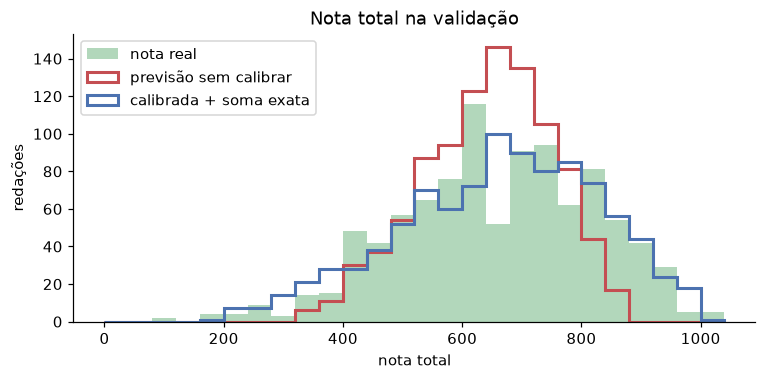

desvio-padrão — real: 164 · sem calibrar: 108 · final: 168


,QWK C1,QWK C2,QWK C3,QWK C4,QWK C5,QWK médio,QWK total,MAE,RMSE
"competências arredondadas, sem calibrar",0.450,0.511,0.428,0.577,0.499,0.493,0.644,90.969,118.826
"competências calibradas, sem soma exata",0.522,0.602,0.539,0.626,0.590,0.576,0.682,109.814,141.573
calibradas + soma exata (receita final),0.506,0.585,0.534,0.603,0.591,0.564,0.692,101.155,129.983


In [10]:
r = dev["ExtraTrees"]
real_dev = Y[pos["dev"]].sum(axis=1)
fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.arange(0, 1041, 40)
ax.hist(real_dev, bins=bins, alpha=0.45, label="nota real", color="#55A868")
ax.hist(r["t_cru"], bins=bins, histtype="step", lw=2, label="previsão sem calibrar", color="#C44E52")
ax.hist(r["niveis"].sum(axis=1) * 40, bins=bins, histtype="step", lw=2, label="calibrada + soma exata", color="#4C72B0")
ax.set(title="Nota total na validação", xlabel="nota total", ylabel="redações")
ax.legend()
plt.show()
print(f"desvio-padrão — real: {real_dev.std():.0f} · sem calibrar: {r['t_cru'].std():.0f} · "
      f"final: {(r['niveis'].sum(axis=1) * 40).std():.0f}")

sem_cal = np.clip(np.rint(r["c_cru"]), 0, 5).astype(int)
so_cal = np.clip(np.rint(r["c_hat"]), 0, 5).astype(int)
pd.DataFrame({
    "competências arredondadas, sem calibrar": metricas(Y[pos["dev"]], sem_cal),
    "competências calibradas, sem soma exata": metricas(Y[pos["dev"]], so_cal),
    "calibradas + soma exata (receita final)": metricas(Y[pos["dev"]], r["niveis"]),
}).T

Sem calibrar, as previsões ficam espremidas (desvio-padrão de 108 pontos, contra 164 das notas reais): nenhuma passa de
880. Esse modelo tem o **menor MAE** (91), porque prever perto da média custa pouco no erro absoluto, mas o **pior QWK**
(0,64), porque não separa bem as redações fracas das boas. A calibração devolve a dispersão e sobe o QWK total para
0,68, ao custo de mais erro absoluto (MAE 110): o modelo passa a arriscar notas altas e baixas e, quando erra, erra mais
longe. A soma exata recupera parte desse erro (MAE 101) e dá o melhor QWK total (0,69). Para o aluno, uma nota que
nunca passa de 880 seria pior do que um erro médio alguns pontos maior.

## 7. Avaliação final no teste

Com a receita escolhida, o modelo é ajustado em treino + validação e avaliado **uma vez** no teste (976 redações).

In [11]:
t0 = time.perf_counter()
aj_final = np.concatenate([pos["train"], pos["dev"]])
teste = treina_e_avalia("ExtraTrees", aj_final, pos["test"])
print(f"treino + validação → teste: {time.perf_counter() - t0:.0f}s")
m_teste = metricas(Y[pos["test"]], teste["niveis"], boot=2000)
pd.DataFrame({"ExtraTrees (teste oficial)": m_teste}).T

treino + validação → teste: 406s


,QWK C1,QWK C2,QWK C3,QWK C4,QWK C5,QWK médio,QWK total,MAE,RMSE,IC 95% QWK total
ExtraTrees (teste oficial),0.523,0.593,0.555,0.666,0.602,0.588,0.726,96.926,124.946,0.695–0.754


**Comparação com a literatura no mesmo corpus e na mesma divisão** (Marinho, Anchiêta & Moura, *JIDM* 2022, Tabelas
XI e XII):

| | C1 | C2 | C3 | C4 | C5 | QWK total | RMSE |
|---|---:|---:|---:|---:|---:|---:|---:|
| Amorim & Veloso (2017) | 0,39 | 0,46 | 0,40 | 0,38 | 0,34 | 0,49 | 161 |
| Fonseca et al. (2018) | 0,44 | 0,48 | 0,42 | 0,47 | 0,38 | 0,53 | 157 |

Como referência humana, dois corretores concordam entre si com QWK total de cerca de 0,69 (Barbosa & Mauá, PROPOR
2026, em outro conjunto de dados).

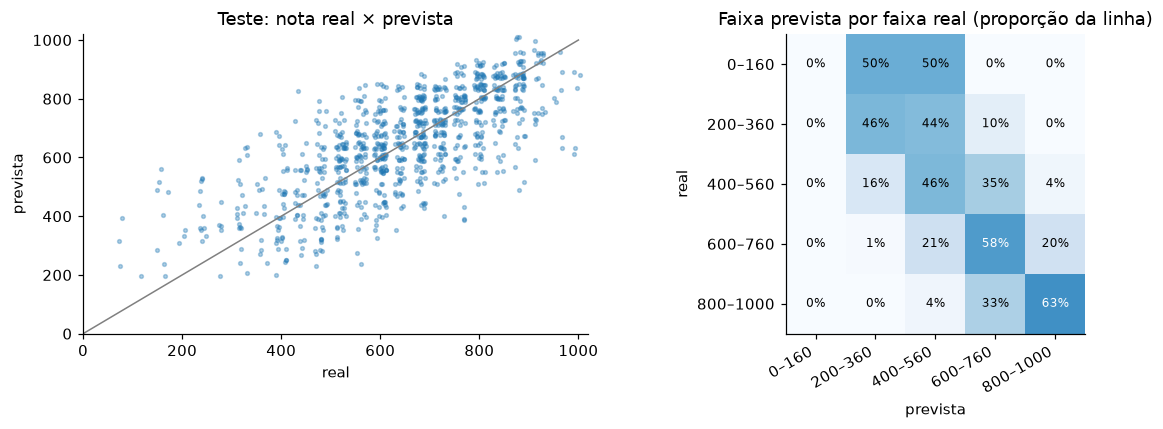

correlação de Pearson entre real e prevista: 0.73


,redações,erro médio
até 440,128.0,82.500
480 a 680,470.0,15.745
720 ou mais,378.0,-37.884


In [12]:
real_t, prev_t = Y[pos["test"]].sum(axis=1), teste["niveis"].sum(axis=1) * 40
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
rng = np.random.default_rng(0)
axs[0].scatter(real_t + rng.uniform(-12, 12, len(real_t)), prev_t + rng.uniform(-12, 12, len(prev_t)), s=6, alpha=0.35)
axs[0].plot([0, 1000], [0, 1000], color="gray", lw=1)
axs[0].set(title="Teste: nota real × prevista", xlabel="real", ylabel="prevista", xlim=(0, 1020), ylim=(0, 1020))
rotulos = ["0–160", "200–360", "400–560", "600–760", "800–1000"]
cortes = [-1, 180, 380, 580, 780, 1001]
contagem = pd.crosstab(pd.cut(real_t, cortes, labels=rotulos), pd.cut(prev_t, cortes, labels=rotulos),
                       dropna=False).reindex(index=rotulos, columns=rotulos, fill_value=0)
mat = contagem.div(contagem.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
im = axs[1].imshow(mat.to_numpy(), cmap="Blues", vmin=0, vmax=1)
axs[1].set(xticks=range(5), yticks=range(5), yticklabels=mat.index,
           title="Faixa prevista por faixa real (proporção da linha)", xlabel="prevista", ylabel="real")
axs[1].set_xticklabels(mat.columns, rotation=30, ha="right")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        axs[1].text(j, i, f"{mat.iat[i, j]:.0%}", ha="center", va="center", fontsize=8,
                    color="white" if mat.iat[i, j] > 0.5 else "black")
plt.tight_layout()
plt.show()
print(f"correlação de Pearson entre real e prevista: {np.corrcoef(real_t, prev_t)[0, 1]:.2f}")
vies_por_faixa(Y[pos["test"]], teste["niveis"])

O erro não é uniforme: as redações fracas são **superestimadas** e as boas, **subestimadas**. É regressão à média: com
uma correlação em torno de 0,7 entre previsão e nota real, quem está longe da média é puxado para ela. A calibração da
seção 6 devolve a dispersão às notas, mas não consegue saber *quais* redações estão nas pontas. No laboratório, curvas
que esticam as pontas só trocaram um erro por outro.

## 8. Temas que o modelo nunca viu

Na divisão oficial, quase todo tema do teste também aparece no treino. No uso real, o aluno pode escrever sobre um tema
novo. Para medir isso, treino + validação são divididos em 5 dobras **por tema** (`GroupKFold`): cada redação é
avaliada por um modelo que não viu nenhuma redação do mesmo tema.

In [13]:
if RODAR_TEMAS_INEDITOS:
    t0 = time.perf_counter()
    niv_grupo = np.empty((len(aj_final), 5), dtype=int)
    for k, (itr, iva) in enumerate(GroupKFold(n_splits=5).split(aj_final, groups=TEMAS[aj_final])):
        niv_grupo[iva] = treina_e_avalia("ExtraTrees", aj_final[itr], aj_final[iva])["niveis"]
        print(f"dobra {k + 1}/5 ({time.perf_counter() - t0:.0f}s)")
    display(pd.DataFrame({
        "validação (temas já vistos)": metricas(Y[pos["dev"]], dev["ExtraTrees"]["niveis"]),
        "5 dobras por tema (temas inéditos)": metricas(Y[aj_final], niv_grupo),
    }).T)

dobra 1/5 (240s)


dobra 2/5 (449s)


dobra 3/5 (670s)


dobra 4/5 (904s)


dobra 5/5 (1245s)


,QWK C1,QWK C2,QWK C3,QWK C4,QWK C5,QWK médio,QWK total,MAE,RMSE
validação (temas já vistos),0.506,0.585,0.534,0.603,0.591,0.564,0.692,101.155,129.983
5 dobras por tema (temas inéditos),0.493,0.568,0.532,0.614,0.556,0.553,0.684,101.037,130.446


Em temas inéditos, o QWK total cai pouco (de 0,692 para 0,684) e o MAE fica igual (101): o modelo não depende de ter
visto o tema. É o esperado pelo desenho: as perguntas do Jev falam da redação, não de um tema específico, e o TF-IDF só
usa termos que aparecem em vários temas.

## 9. O que o modelo aprendeu

Importância por permutação no teste, para o modelo do **total**: quanto o erro médio (MAE) piora quando os valores de
uma coluna são embaralhados entre as redações. Diferente da importância por impureza das árvores, ela mede o efeito
na previsão de dados novos. Colunas parecidas dividem a importância entre si (embaralhar uma, a outra ainda carrega a
informação), então a soma por grupo diz mais que o ranking individual.

permutação: 43s


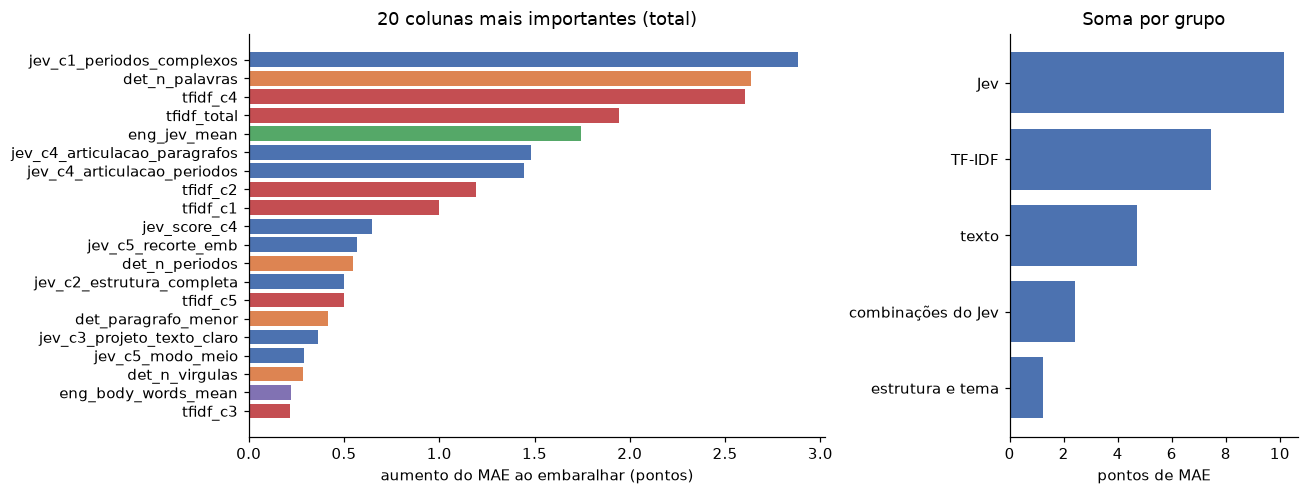

In [14]:
t0 = time.perf_counter()
y_aj_tot = Y[aj_final].sum(axis=1)
modelo_total = novo_modelo("ExtraTrees").fit(teste["x_aj"], y_aj_tot)
imp = permutation_importance(modelo_total, teste["x_av"], real_t, scoring="neg_mean_absolute_error",
                             n_repeats=5, random_state=0, n_jobs=1)
nomes = COLS_ET + ["tfidf_c1", "tfidf_c2", "tfidf_c3", "tfidf_c4", "tfidf_c5", "tfidf_total"]
importancia = pd.Series(imp.importances_mean, index=nomes).sort_values(ascending=False)
print(f"permutação: {time.perf_counter() - t0:.0f}s")


def grupo(c):
    if c.startswith("eng_jev_"):
        return "combinações do Jev"
    return {"jev": "Jev", "det": "texto", "eng": "estrutura e tema", "tfidf": "TF-IDF"}[c.split("_")[0]]


fig, axs = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [2, 1]})
top = importancia.head(20)[::-1]
axs[0].barh(top.index, top.values, color=[{"Jev": "#4C72B0", "texto": "#DD8452", "estrutura e tema": "#8172B3",
                                           "combinações do Jev": "#55A868", "TF-IDF": "#C44E52"}[grupo(c)] for c in top.index])
axs[0].set(title="20 colunas mais importantes (total)", xlabel="aumento do MAE ao embaralhar (pontos)")
por_grupo = importancia.clip(lower=0).groupby(grupo).sum().sort_values()
axs[1].barh(por_grupo.index, por_grupo.values, color="#4C72B0")
axs[1].set(title="Soma por grupo", xlabel="pontos de MAE")
plt.tight_layout()
plt.show()

O grupo mais importante é o do Jev (cerca de 10 pontos de MAE somados), seguido do TF-IDF (cerca de 7) e das medidas do
texto (cerca de 5). A coluna mais importante sozinha é `jev_c1_periodos_complexos` (o Jev avaliando se a redação
articula períodos complexos), seguida do tamanho do texto (`det_n_palavras`) e da previsão do TF-IDF para a C4 (coesão).
Como colunas parecidas dividem a importância entre si, um conceito medido por várias colunas aparece mais baixo no
ranking do que realmente pesa.

## 10. Modelo final e paridade com o bot

O modelo do bot é treinado nas **6.475 redações** (treino + validação + teste), com a mesma receita: colunas TF-IDF
fora da amostra para treinar as árvores, calibração com previsões fora da amostra e os seis ExtraTrees ajustados em
tudo. A célula abaixo monta esse modelo no mesmo formato do artefato que o bot carrega
(`src/correction/hybrid/model.py`).

O artefato de produção não é publicado no repositório. Se ele estiver na máquina (`src/correction/hybrid/artifacts/`),
a última célula confere que o modelo daqui e o do bot dão **as mesmas notas**.

In [15]:
t0 = time.perf_counter()
todas = np.arange(len(df))
y6 = np.column_stack([Y, Y.sum(axis=1)])
tf_oof, _ = tfidf_meta(TEXTOS, TEMAS, Y, TEXTOS[:1])
vec_final, ridges_final = tfidf_ridge(TEXTOS, TEMAS, y6, None, devolver_objetos=True)
x_todas = np.column_stack([X_ET, tf_oof])
oof_c, oof_t = np.empty((len(df), 5)), np.empty(len(df))
for f in dobras(len(df)):
    tr = np.setdiff1d(todas, f)
    oof_c[f], oof_t[f] = ajusta_e_preve("ExtraTrees", x_todas[tr], Y[tr], x_todas[f])
y25 = np.clip(np.rint(Y.sum(axis=1) / 40), 0, 25)
modelo_final = {
    "cols": COLS_ET,
    "tfidf_cols": ["tfidf_c1", "tfidf_c2", "tfidf_c3", "tfidf_c4", "tfidf_c5", "tfidf_total"],
    "tfidf_vectorizer": vec_final,
    "tfidf_ridges": ridges_final,
    "et_comps": [novo_modelo("ExtraTrees").fit(x_todas, Y[:, j]) for j in range(5)],
    "et_total": novo_modelo("ExtraTrees").fit(x_todas, Y.sum(axis=1)),
    "cal_comps": [list(ajusta_match_sd(oof_c[:, j], Y[:, j] // 40)) for j in range(5)],
    "cal_total": list(ajusta_match_sd(oof_t / 40, y25)),
}
print(f"modelo final em {len(df)} redações: {time.perf_counter() - t0:.0f}s")


def prever_niveis(m, linhas):
    # Mesma sequência de src/correction/hybrid/model.py (predict_levels), em lote.
    x = feats.loc[linhas, m["cols"]].to_numpy(float)
    xt = m["tfidf_vectorizer"].transform(TEXTOS[linhas])
    row = np.column_stack([x] + [r.predict(xt) for r in m["tfidf_ridges"]])
    c_hat = np.column_stack([a + b * est.predict(row) / 40 for (a, b), est in zip(m["cal_comps"], m["et_comps"])])
    a, b = m["cal_total"]
    t = np.clip(np.rint(a + b * m["et_total"].predict(row) / 40), 0, 25).astype(int)
    return np.array([reconcile_qp(list(c), int(tt)) for c, tt in zip(c_hat, t)])

modelo final em 6475 redações: 872s


In [16]:
artefato = RAIZ / "src" / "correction" / "hybrid" / "artifacts" / "model.joblib"
if artefato.exists():
    import joblib

    bot = joblib.load(artefato)
    amostra = np.random.default_rng(0).choice(len(df), 500, replace=False)
    iguais = (prever_niveis(modelo_final, amostra) == prever_niveis(bot, amostra)).all(axis=1).mean()
    print(f"colunas iguais às do bot: {bot['cols'] == modelo_final['cols']}")
    print(f"redações com as 5 notas idênticas às do bot (amostra de 500): {iguais:.0%}")
else:
    print("Artefato de produção ausente (ele não é publicado). Para usar o modelo daqui no bot: "
          "joblib.dump(modelo_final, artefato, compress=3)")

colunas iguais às do bot: True
redações com as 5 notas idênticas às do bot (amostra de 500): 100%


## 11. Limitações

- **Viés nas pontas** (seção 7): redações fracas são superestimadas e as boas, subestimadas. É a maior fraqueza do
  modelo e não some com mais dados do mesmo tipo.
- **O Essay-BR é texto digitado.** No bot, o texto vem da leitura (OCR) de uma foto de manuscrito. O efeito dos erros
  de leitura sobre a nota ainda não foi medido.
- **Notas de um site, não do ENEM.** As notas do corpus vêm dos corretores do site, não da banca oficial, que usa dois
  corretores e desempate. O modelo aprende o critério desses corretores.
- **Depende do Jev.** As colunas vêm de um serviço externo numa versão fixa (`jev-1.14.0`). Outra versão pode
  responder diferente, e o modelo precisaria ser retreinado.
- **Fora deste notebook:** a nota zero (portão de regras da Cartilha do INEP) e as pistas para o comentário do LLM
  (checklist). As regras estão em `src/correction/hybrid/scoring.py`.